In [28]:
%% Homework 5
% Due:
% Ely Dawson

%% “I certify that this represents my own work and that I have not
%% worked with classmates or other individuals to complete this assignment.”

In [27]:
%% 1: Make a preliminary assessment of the data.
% First, plot time series of the total wind speed (“WSPD”), 
% zonal wind (“UWND”), and meridional wind (“VWND”).
%% What is the time interval between data points? 
% As the data step is 0.0069444444 days, which converts to 10 minutes,
% we know that the data is taken in 10 minute intervals over this 
% given time series. 

%% What is the time gap between the data files? 
% DM134A to DM183A: 9.50 hours
% DM183A to DM231A: 22.17 hours

%% How are gaps in the data handled?
% Each file is interpolated separately and plotted as its own line, 
% so the plot doesn’t connect the end of one file to the start of the next.
% As of right now, I don't have the data as one continuous time series. 

In [41]:
dataDir = fullfile(getenv('HOME'), 'SIO221a_Github_code_2026', ...
    'homework', 'HW5_data');

files = {
    'DM134A', 'OS_T8S110W_DM134A-20150425_D_WIND_10min.nc';
    'DM183A', 'OS_T8S110W_DM183A-20160321_D_WIND_10min.nc';
    'DM231A', 'OS_T8S110W_DM231A-20170606_D_WIND_10min.nc'
};

wind = struct();

for k = 1:size(files, 1)
    deployment = files{k, 1};
    filePath = fullfile(dataDir, files{k, 2});

    info = ncinfo(filePath);
    names = {info.Variables.Name};
    fields = matlab.lang.makeUniqueStrings(matlab.lang.makeValidName(names));

    timeIndex = find(strcmpi(names, 'time'), 1);

    timeInfo = info.Variables(timeIndex);

    timeDimName = timeInfo.Dimensions(1).Name;
    time = ncread(filePath, timeInfo.Name);
    time = double(time(:));

    data = struct();
    for j = 1:numel(names)
        values = ncread(filePath, names{j});
        dimNames = {info.Variables(j).Dimensions.Name};
        timeDim = find(strcmp(dimNames, timeDimName), 1);

        if j ~= timeIndex && ~isempty(timeDim) && ...
                isfloat(values) && any(isnan(values(:)))
            values = fillmissing(values, 'linear', timeDim, ...
                'SamplePoints', time, 'EndValues', 'none');
        end

        data.(fields{j}) = values;
    end

    wind.(deployment).data = data;
    wind.(deployment).info = info;
end

% Show the loaded variable names for the first deployment.
fieldnames(wind.DM134A.data)

ans = 12×1 cell array
    {'TIME'     }
    {'HEIGHT'   }
    {'LATITUDE' }
    {'LONGITUDE'}
    {'WDIR'     }
    {'WDIR_QC'  }
    {'WDIR_DM'  }
    {'WSPD'     }
    {'WSPD_QC'  }
    {'WSPD_DM'  }
    {'UWND'     }
    {'VWND'     }

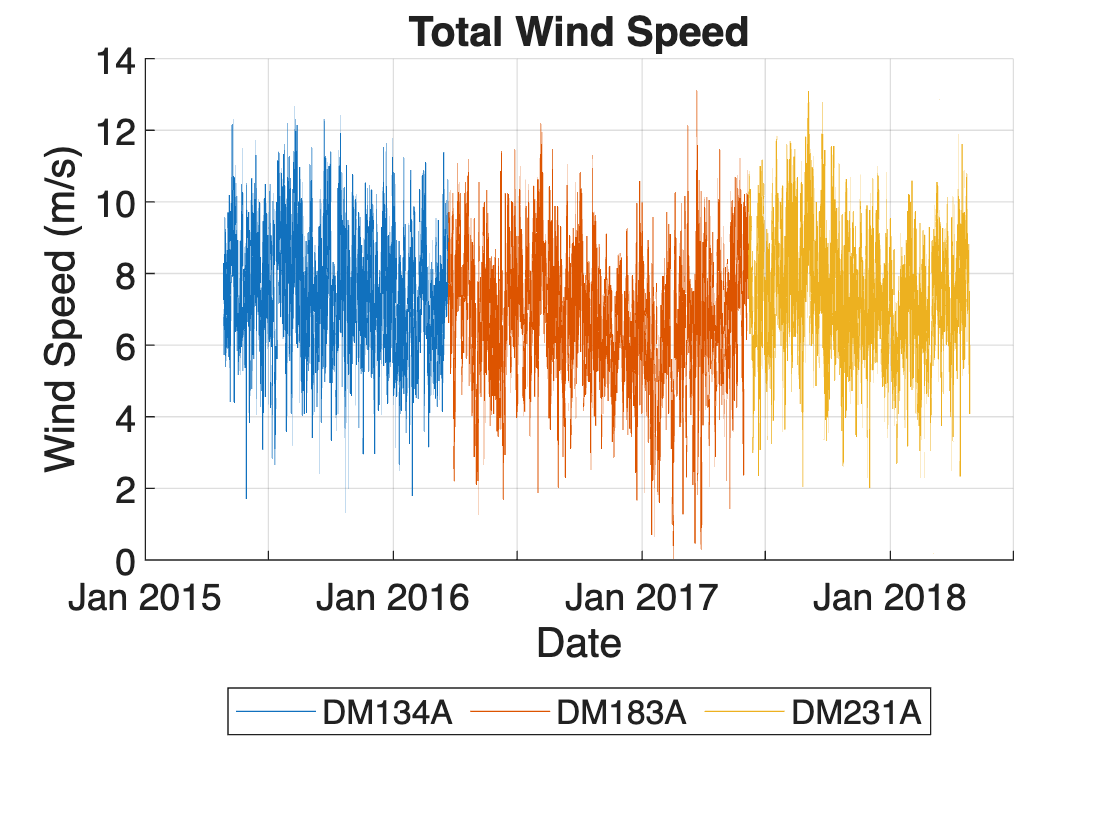

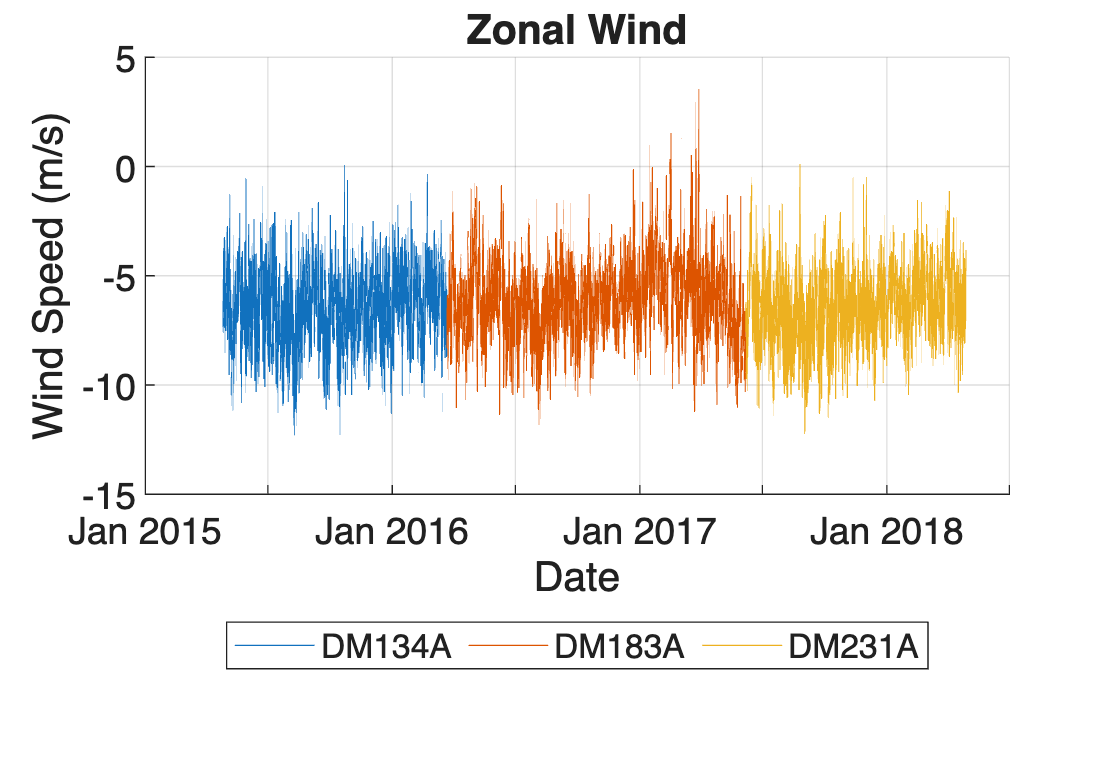

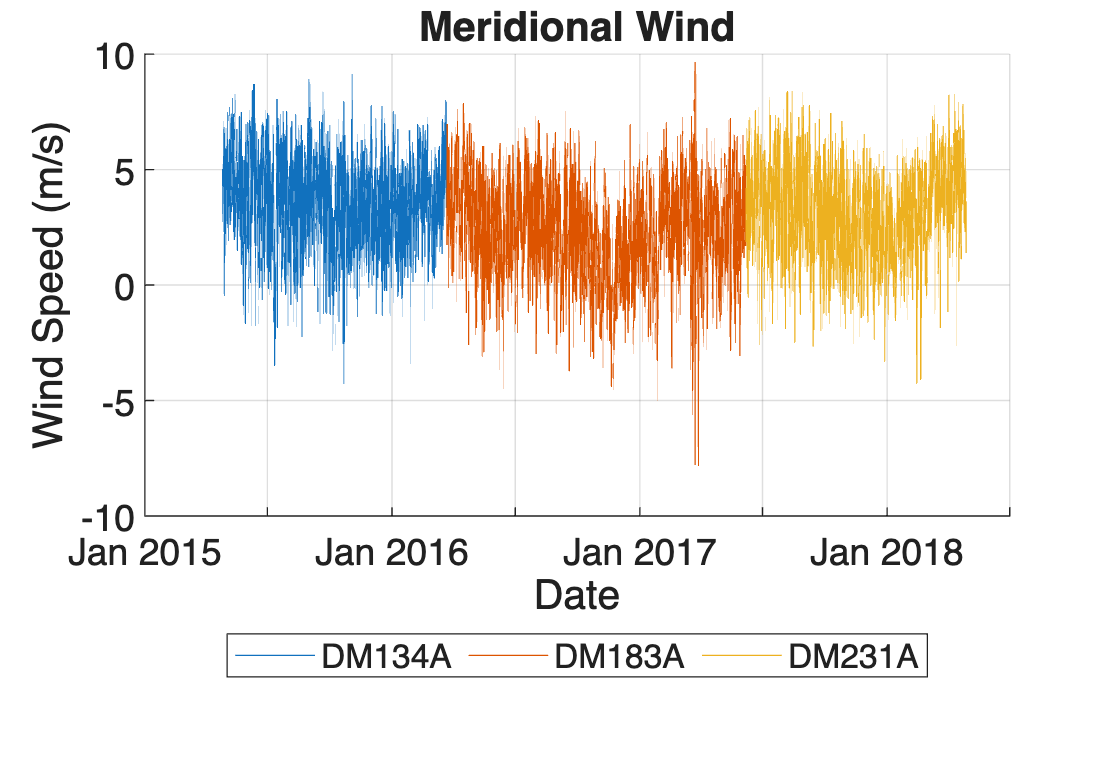

DM134A: 10 complete 60-day segments
DM134A: median step = 0.0069444444, min = 0.0069444444, max = 0.0069444444 (days since 1950-01-01T00:00:00Z)
DM183A: 13 complete 60-day segments
DM183A: median step = 0.0069444444, min = 0.0069444444, max = 0.0069444444 (days since 1950-01-01T00:00:00Z)
DM231A: 9 complete 60-day segments
DM231A: median step = 0.0069444444, min = 0.0069444444, max = 0.0069444444 (days since 1950-01-01T00:00:00Z)
DM134A to DM183A: 9.50 hours
DM183A to DM231A: 22.17 hours


In [42]:
%% Plot wind time series and check the sampling interval

windVars = {'WSPD', 'UWND', 'VWND'};
plotTitles = {'Total Wind Speed', 'Zonal Wind', 'Meridional Wind'};

ax = gobjects(3, 1);

for j = 1:numel(windVars)
    fig = figure('Name', plotTitles{j});
    ax(j) = axes('Parent', fig);
    hold(ax(j), 'on');
    grid(ax(j), 'on');
    title(ax(j), plotTitles{j});
    ylabel(ax(j), 'Wind Speed (m/s)');
end

drawnow;

for k = 1:size(files, 1)
    deployment = files{k, 1};
    record = wind.(deployment);

    names = {record.info.Variables.Name};
    fields = matlab.lang.makeUniqueStrings(matlab.lang.makeValidName(names));
    timeIndex = find(strcmpi(names, 'time'), 1);
    t = double(record.data.(fields{timeIndex}));
    t = t(:);

    filePath = fullfile(dataDir, files{k, 2});
    timeUnits = ncreadatt(filePath, names{timeIndex}, 'units');
    plotTime = datetime(1950, 1, 1) + days(t);
    recordStart(k) = min(plotTime);
    recordEnd(k) = max(plotTime);

    % 60-day windows with 50% overlap.
    windowLength = days(60);
    windowStep = days(30);
    sampleInterval = minutes(10);

    recordStop = plotTime(end) + sampleInterval;
    windowStarts = plotTime(1):windowStep:(recordStop - windowLength);

    segments.(deployment) = struct('startTime', {}, 'endTime', {}, ...
        'time', {}, 'WSPD', {}, 'UWND', {}, 'VWND', {});

for s = 1:numel(windowStarts)
    startTime = windowStarts(s);
    endTime = startTime + windowLength;
    inWindow = plotTime >= startTime & plotTime < endTime;

    segment.startTime = startTime;
    segment.endTime = endTime;
    segment.time = plotTime(inWindow);

    for j = 1:numel(windVars)
        idx = find(strcmpi(names, windVars{j}), 1);
        y = record.data.(fields{idx});
        segment.(windVars{j}) = y(inWindow);
    end

    segments.(deployment)(s) = segment;
end

fprintf('%s: %d complete 60-day segments\n', deployment, numel(windowStarts));

    dt = diff(t);
    fprintf('%s: median step = %.8g, min = %.8g, max = %.8g (%s)\n', ...
        deployment, median(dt), min(dt), max(dt), timeUnits);

    for j = 1:numel(windVars)
        idx = find(strcmpi(names, windVars{j}), 1);
        y = record.data.(fields{idx});

        plot(ax(j), plotTime, y(:), 'DisplayName', deployment);
    end
end



for k = 1:(size(files, 1) - 1)
    gapHours = hours(recordStart(k + 1) - recordEnd(k));
    fprintf('%s to %s: %.2f hours\n', ...
        files{k, 1}, files{k + 1, 1}, gapHours);
end

linkaxes(ax, 'x');

for j = 1:numel(windVars)
    xtickformat(ax(j), 'MMM yyyy');
    xlabel(ax(j), 'Date');
    legend(ax(j), 'Location', 'southoutside', 'Orientation', 'horizontal');
end

In [37]:
%% 2: Segment the data into 60-day segments with 50% overlap. 
%% How many segments do you have for each of the data files? 
% DM134A: 10 complete 60-day segments
% DM183A: 13 complete 60-day segments
% DM231A: 9 complete 60-day segments

%% How many points are in each segment?
% Each segment has a total of 8640 points. 
% This makes sense as the data is seperated into 10 minute intervals. 
% Based on the equation below, it makes sense why this is the case. 
% 60 days x 24hr/day x 6pts/hr = 8640 pts

% Determine the frequencies (in cycles per day) that you will 
% be able to analyze when you Fourier transform the data.

In [43]:
for k = 1:size(files, 1)
    deployment = files{k, 1};
    counts = arrayfun(@(s) numel(s.time), segments.(deployment));
    fprintf('%s: %s points per segment\n', deployment, mat2str(counts));
end

DM134A: [8640 8640 8640 8640 8640 8640 8640 8640 8640 8640] points per segment
DM183A: [8640 8640 8640 8640 8640 8640 8640 8640 8640 8640 8640 8640 8640] points per segment
DM231A: [8640 8640 8640 8640 8640 8640 8640 8640 8640] points per segment


In [50]:
%% 3: Compute and plot spectra using 3 different approaches, 
%% for the 2015 wind speed record only.
% Compute the spectrum from the raw data, from the detrended data, 
% and from the detrended data with a Hanning window applied. 

%% How does detrending and windowing alter the spectrum in this case?
% Hann windowing tapers the ends of the detrended record toward zero.
% The taper reduces spectral leakage from the ends of the record, 
% thus the effect is most apparent in the fine detail of the spectrum.
% Detrending has its largest visible effect at the lowest frequencies.
% At higher frequencies, the raw and detrended spectra nearly overlap.

Trimmed 0 leading and 24 trailing samples.


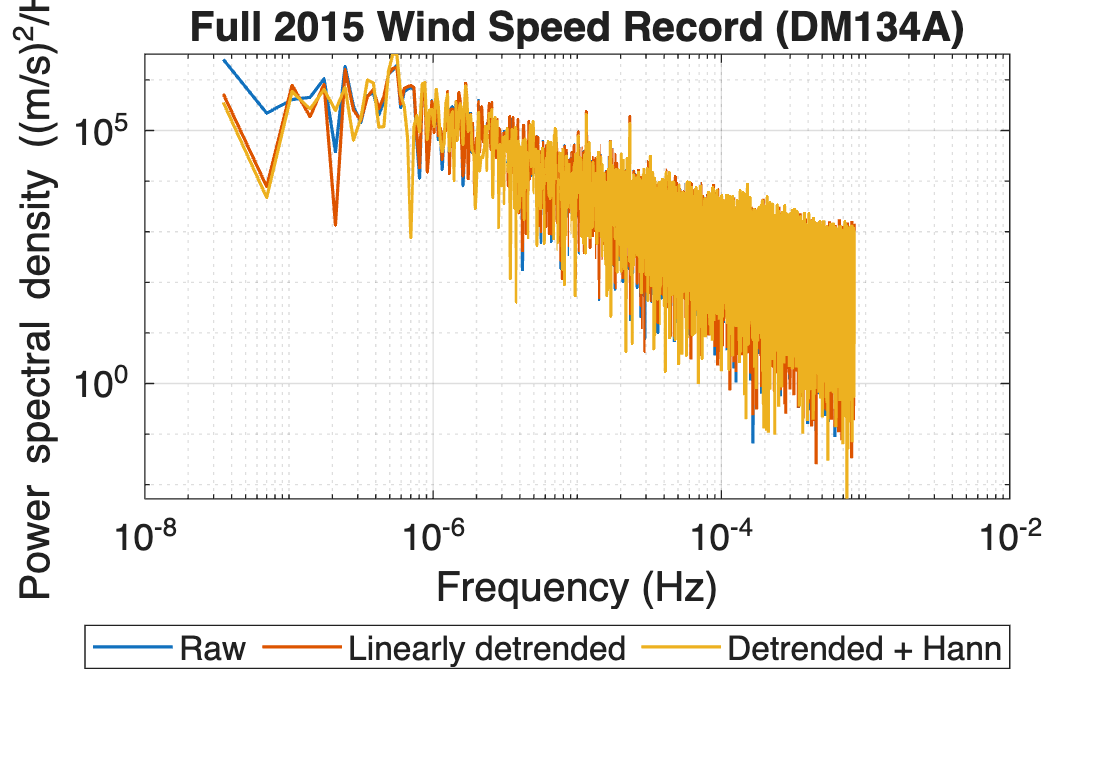

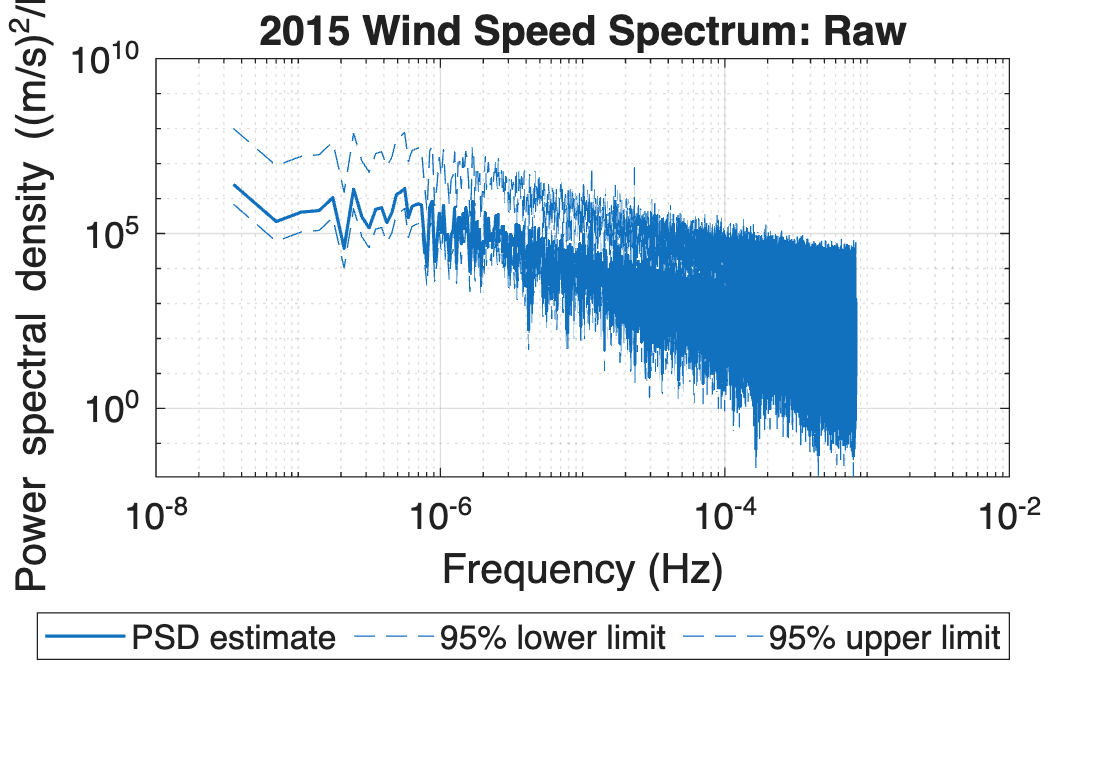

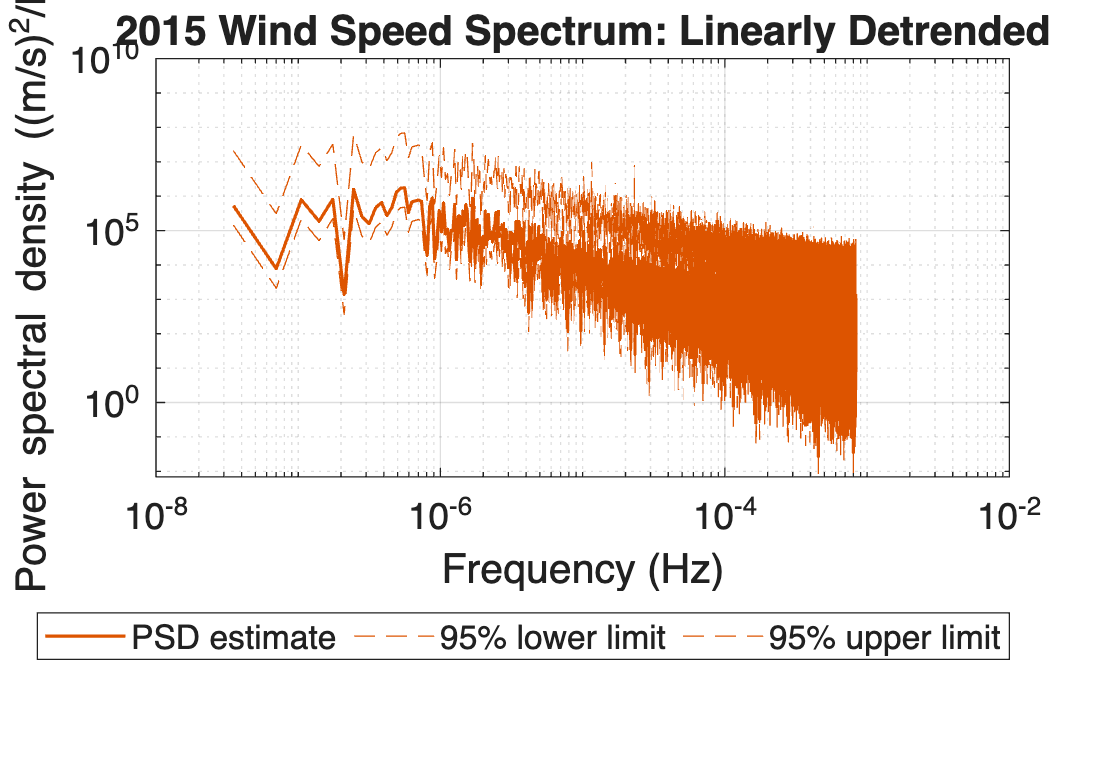

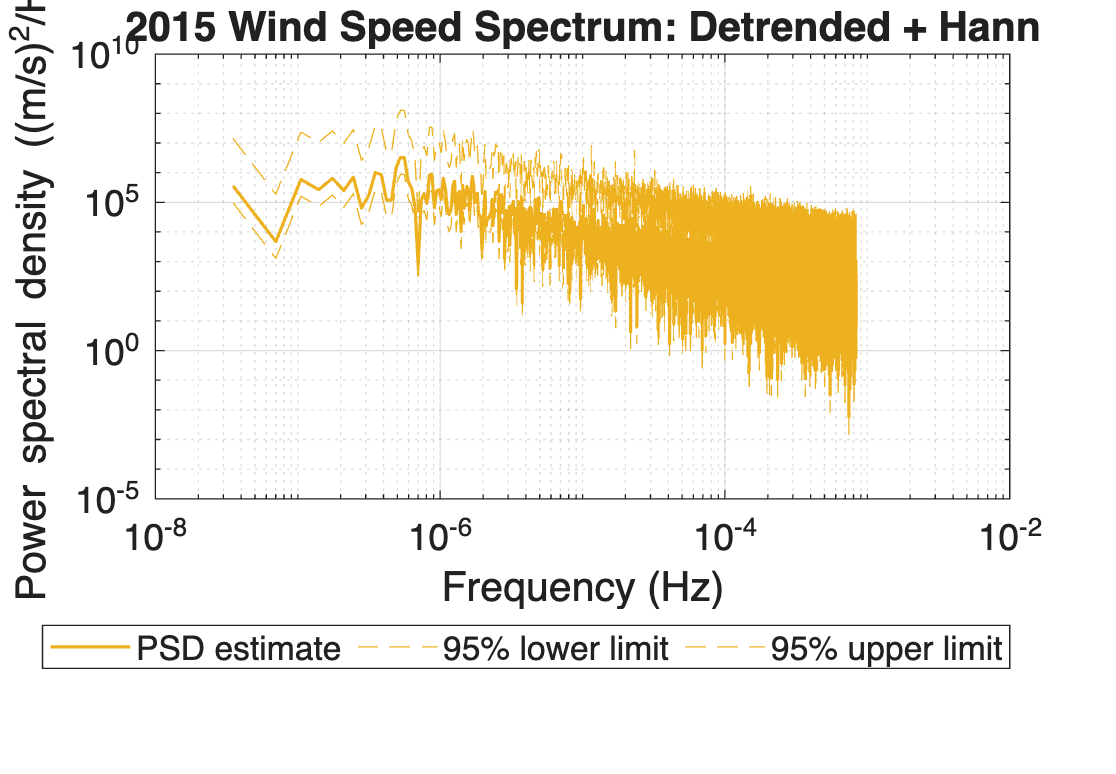

In [52]:
%% Compare wind speed spectra for the full 2015 record
x = double(wind.DM134A.data.WSPD(:));

% Find the first and last valid measurements.
firstValid = find(isfinite(x), 1, 'first');
lastValid = find(isfinite(x), 1, 'last');

fprintf('Trimmed %d leading and %d trailing samples.\n', ...
    firstValid - 1, numel(x) - lastValid);

x = x(firstValid:lastValid);

N = numel(x);
Fs = 1 / 600;  % Sampling frequency in Hz for a 10-minute interval

% Prepare the three versions of the full wind speed record.
xDetrended = detrend(x, 1);
n = (0:N-1)';
hannWindow = 0.5 - 0.5*cos(2*pi*n/N);

signals = [x, xDetrended, xDetrended .* hannWindow];
windowPower = [N, N, sum(hannWindow.^2)];

X = fft(signals, [], 1);
nFreq = floor(N/2) + 1;
f = (0:nFreq-1)' * Fs / N;
P = abs(X(1:nFreq, :)).^2 ./ (Fs * windowPower);

lastBin = nFreq - (mod(N, 2) == 0);
P(2:lastBin, :) = 2 * P(2:lastBin, :);

% Plotting all 3 spectra together
figure('Name', '2015 Wind Speed Spectra');
loglog(f(2:end), P(2:end, :), 'LineWidth', 1.2);
grid on;
xlabel('Frequency (Hz)');
ylabel('Power spectral density ((m/s)^2/Hz)');
title('Full 2015 Wind Speed Record (DM134A)');
legend('Raw', 'Linearly detrended', 'Detrended + Hann', ...
    'Location', 'southoutside', 'Orientation', 'horizontal');

spectrumTitles = {'Raw', 'Linearly Detrended', 'Detrended + Hann'};
colors = lines(3);

% Plotting all 3 spectra seperately 
% Add uncertainty
spectrumTitles = {'Raw', 'Linearly Detrended', 'Detrended + Hann'};
colors = lines(3);

bins = 2:(numel(f) - (mod(N, 2) == 0));

% Chi-square quantiles for 2 degrees of freedom.
chi2Low  = -2 * log(1 - 0.025);
chi2High = -2 * log(1 - 0.975);

for j = 1:numel(spectrumTitles)
    estimate = P(bins, j);
    lower = 2 * estimate / chi2High;
    upper = 2 * estimate / chi2Low;

    figure('Name', spectrumTitles{j}, 'NumberTitle', 'off');
    loglog(f(2:end), P(2:end, j), ...
        'Color', colors(j, :), 'LineWidth', 1.2);
    hold on;
    loglog(f(bins), lower, '--', 'Color', colors(j, :));
    loglog(f(bins), upper, '--', 'Color', colors(j, :));
    grid on;

    xlabel('Frequency (Hz)');
    ylabel('Power spectral density ((m/s)^2/Hz)');
    title(['2015 Wind Speed Spectrum: ' spectrumTitles{j}]);
    legend('PSD estimate', '95% lower limit', '95% upper limit', ...
        'Location', 'southoutside', 'Orientation', 'horizontal');
end

In [53]:
%% 4: Add uncertainty estimates to the 2015 wind speed spectra. 
% Indicate whether you think the uncertainty should differ for the 3 cases.

% I think the uncertainty will differ slightly between each of the cases.
% Detrending changes the lowest-frequency bins, where the approximation is less reliable. 
% Hann windowing reduces leakage but makes neighboring frequency bins more correlated.

In [55]:
%% 5: Compute spectra for wind speed, zonal wind, and meridional wind,
%% using all three data files. 
% Detrend and Hanning window each, and compute the uncertainty estimate.
% First overlay the multi-year wind-speed
% spectrum over the 2015-only spectrum you computed earlier. 
%% How do they differ? Why? 
% The multi-year wind-speed spectrum is greatly narrowed in it's uncertainty.
% Using the 60 day spectra also makes the curve much cleaner and less jagged. 
% That being said, both the 2015 and multi-year spectra follow a very similar trend line.

%% Can the differences be explained by differences in the uncertainties?
% Both spectra show a similar overall shape. The overlay alone cannot
% establish whether any sustained differences reflect changes in the wind,
% because the estimates share 2015 data and use different window lengths.

% Then, compare the three multi-year spectra 
% (wind speed, zonal, meridional) to each other. 
% Examine the peaks at the diurnal and semi-diurnal frequencies. 
%% How do they differ? 
% We can see from the last figure, that the meridional wind has the
% strongest diurnal signal, whereas the zonal wind has a stronger
% semi-diurnal signal when compared to the meridional. 
% However, this semi-diurnal signal is not very significantly different. 

%% Are the differences statistically significant? 
% The difference for the diurnal signal is statistically significant. 
% WSPD minus VWND: mean difference = -0.0429, adjusted p = 0.0623
% UWND minus VWND: mean difference = -0.043, adjusted p = 0.0265
% We can see from the p-values, that the meridional win is significantly different
% when compared to the other two values.
% The semi-diurnal frequency was not nearly as clear. 
% WSPD minus UWND: mean difference = -0.00256, adjusted p = 0.683
% WSPD minus VWND: mean difference = -0.00112, adjusted p = 1
% UWND minus VWND: mean difference = +0.00144, adjusted p = 1
% This shows that none of the variables are significantly different from eachother. 

%% What do you hypothesize might account for them?
% Daily solar heating may drive north-south pressure gradients and
% boundary layer circulation, producing a stronger diurnal signal in
% VWND than in UWND. If the prevailing wind is mainly zonal, a daily
% oscillation in VWND can change wind direction more than total speed,
% which could explain why the diurnal signal is weaker in WSPD.

WSPD: 32 segments, 60.9 effective degrees of freedom


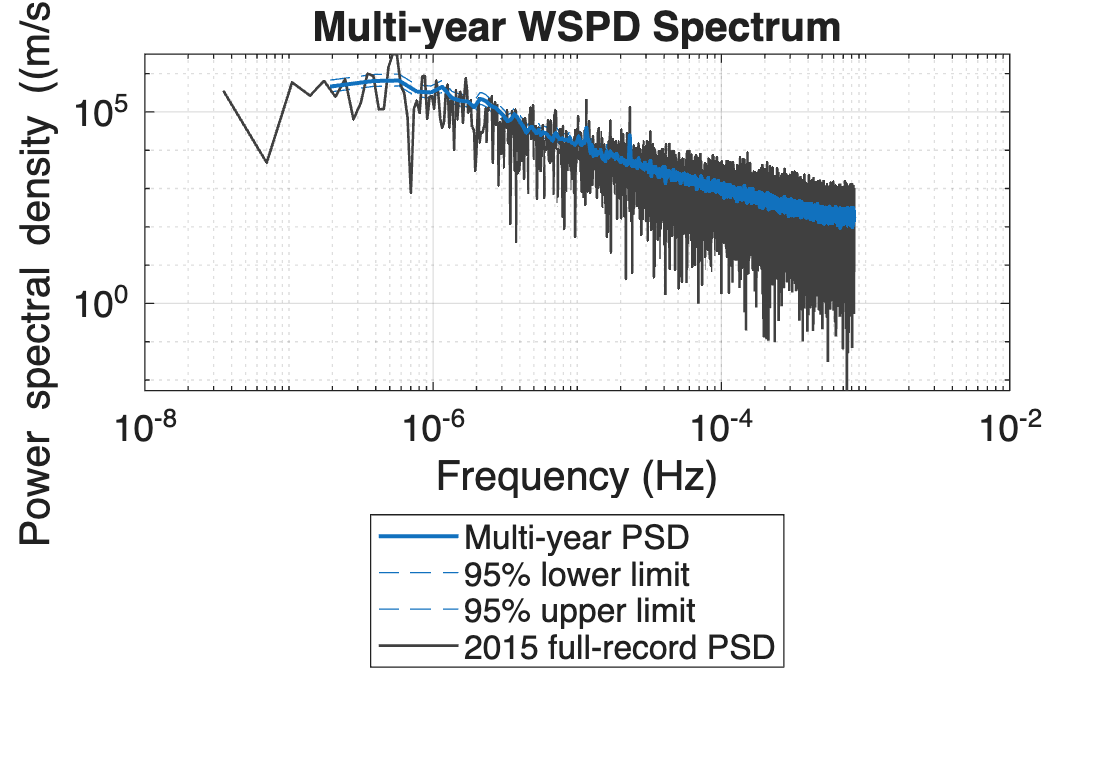

UWND: 32 segments, 60.9 effective degrees of freedom


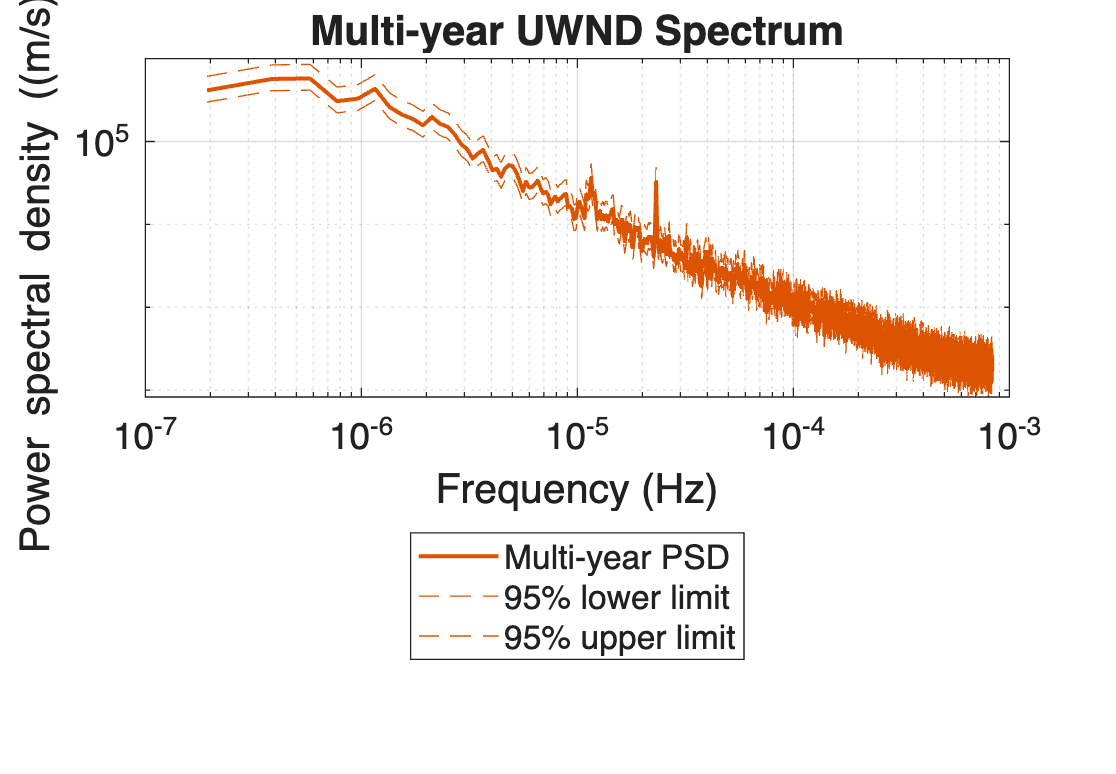

VWND: 32 segments, 60.9 effective degrees of freedom


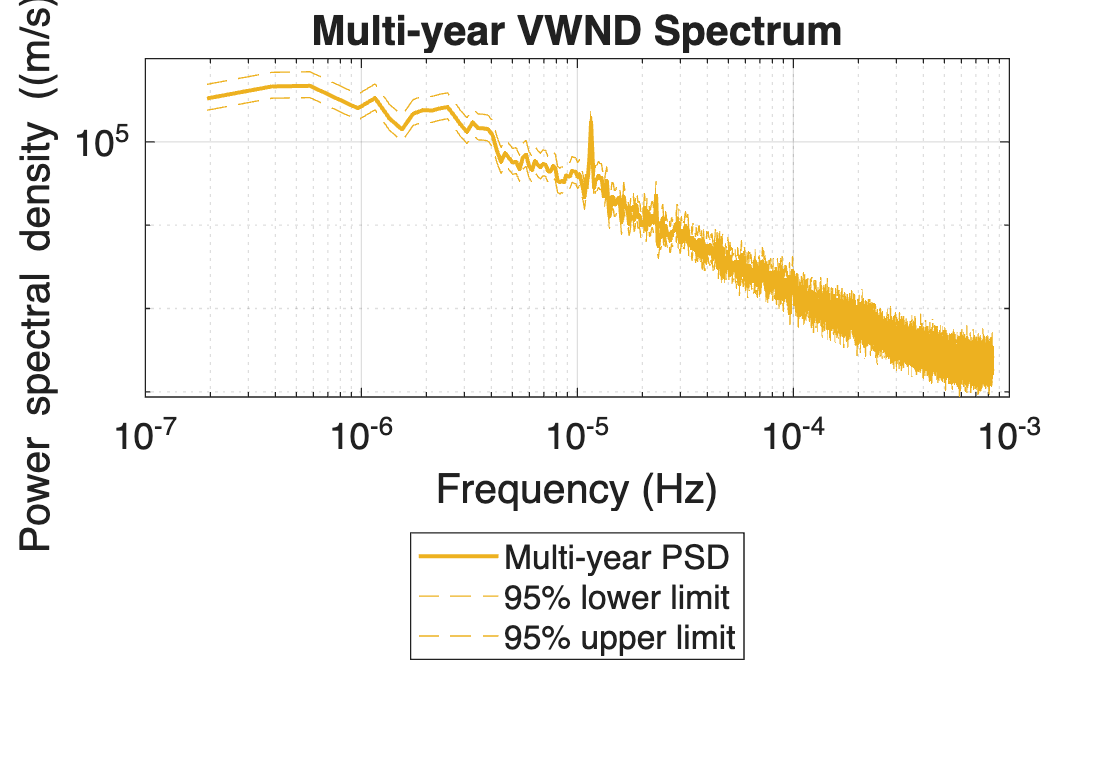

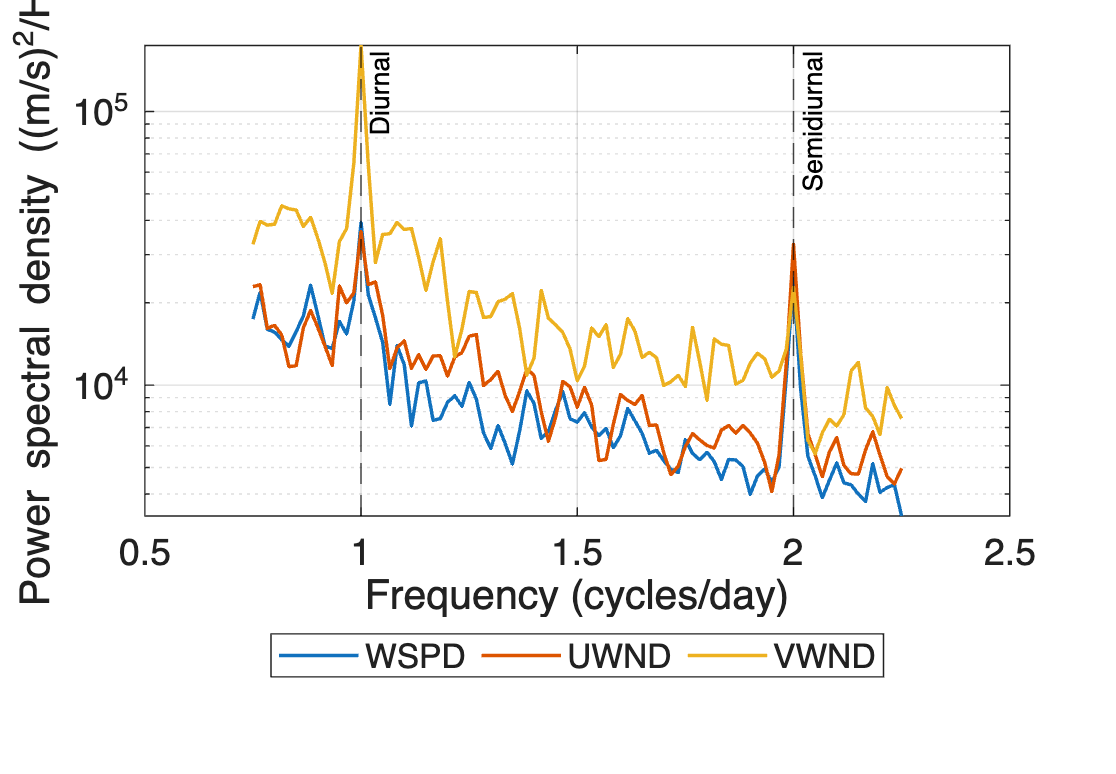

In [63]:
%% 5: Multi-year wind spectra and uncertainty

windVars = {'WSPD', 'UWND', 'VWND'};
Fs = 1 / 600; % Sampling frequency in Hz
nSeg = 60 * 24 * 6; % Samples per 60-day segment
hop = nSeg / 2;
nFreq = nSeg / 2 + 1;
fMulti = (0:nFreq-1)' * Fs / nSeg;

n = (0:nSeg-1)';
w = 0.5 - 0.5*cos(2*pi*n/nSeg);
windowPower = sum(w.^2);

% Normalized overlap between adjacent Hann windows.
rho = sum(w(1:end-hop) .* w(hop+1:end)) / windowPower;

psdSum = zeros(nFreq, numel(windVars));
segmentCount = zeros(1, numel(windVars));
adjacentPairs = zeros(1, numel(windVars));

for k = 1:size(files, 1)
    deployment = files{k, 1};
    recordSegments = segments.(deployment);
    previousUsed = false(1, numel(windVars));

    for s = 1:numel(recordSegments)
        seg = recordSegments(s);
        regularGrid = numel(seg.time) == nSeg && ...
            all(abs(seconds(diff(seg.time(:))) - 600) < 0.1);
        used = false(1, numel(windVars));

        if regularGrid
            for j = 1:numel(windVars)
                x = double(seg.(windVars{j})(:));

                if numel(x) == nSeg && all(isfinite(x))
                    X = fft(detrend(x, 1) .* w);
                    psd = abs(X(1:nFreq)).^2 / (Fs * windowPower);
                    psd(2:end-1) = 2 * psd(2:end-1);

                    psdSum(:, j) = psdSum(:, j) + psd;
                    segmentCount(j) = segmentCount(j) + 1;
                    used(j) = true;
                end
            end
        end

        adjacentPairs = adjacentPairs + (previousUsed & used);
        previousUsed = used;
    end
end

multiPSD = psdSum ./ segmentCount;

% Approximate effective degrees of freedom, accounting for overlap.
nu = 2 * segmentCount.^2 ./ ...
    (segmentCount + 2 * adjacentPairs * rho^2);

qLow = 2 * gammaincinv(0.025, nu / 2);
qHigh = 2 * gammaincinv(0.975, nu / 2);
multiLower = multiPSD .* (nu ./ qHigh);
multiUpper = multiPSD .* (nu ./ qLow);

bins = 2:nFreq-1;
colors = lines(3);

for j = 1:numel(windVars)
    fprintf('%s: %d segments, %.1f effective degrees of freedom\n', ...
        windVars{j}, segmentCount(j), nu(j));

    figure('Name', ['Multi-year ' windVars{j}], 'NumberTitle', 'off');

hMulti = loglog(fMulti(bins), multiPSD(bins, j), ...
    'Color', colors(j, :), 'LineWidth', 1.5);
hold on;

hLower = loglog(fMulti(bins), multiLower(bins, j), '--', ...
    'Color', colors(j, :));
hUpper = loglog(fMulti(bins), multiUpper(bins, j), '--', ...
    'Color', colors(j, :));

legendHandles = [hMulti, hLower, hUpper];
labels = {'Multi-year PSD', '95% lower limit', '95% upper limit'};

if j == 1
    h2015 = loglog(f(2:end), P(2:end, 3), ...
        'Color', [0.25 0.25 0.25], 'LineWidth', 1);
    legendHandles(end+1) = h2015;
    labels{end+1} = '2015 full-record PSD';

    uistack(hMulti, 'top');
end

grid on;
xlabel('Frequency (Hz)');
ylabel('Power spectral density ((m/s)^2/Hz)');
title(['Multi-year ' windVars{j} ' Spectrum']);
legend(legendHandles, labels, 'Location', 'southoutside');
end

%% Compare the multi-year spectra near 1 and 2 cycles/day
fPerDay = fMulti * 86400;
nearPeaks = fPerDay >= 0.75 & fPerDay <= 2.25;

figure('Name', 'Diurnal and Semidiurnal Wind Spectra', ...
    'NumberTitle', 'off');
semilogy(fPerDay(nearPeaks), multiPSD(nearPeaks, :), 'LineWidth', 1.3);
hold on;
xline(1, 'k--', 'Diurnal', 'HandleVisibility', 'off');
xline(2, 'k--', 'Semidiurnal', 'HandleVisibility', 'off');
grid on;
xlabel('Frequency (cycles/day)');
ylabel('Power spectral density ((m/s)^2/Hz)');
legend(windVars, 'Location', 'southoutside', 'Orientation', 'horizontal');

In [64]:
%% Compare diurnal and semidiurnal band power by deployment

df = fMulti(2) - fMulti(1);
targetFreq = [1, 2] / 86400;
bandNames = {'Diurnal', 'Semidiurnal'};
bandBins = zeros(3, 2);

for b = 1:2
    [~, centerBin] = min(abs(fMulti - targetFreq(b)));
    bandBins(:, b) = (centerBin-1:centerBin+1)';
end

% Dimensions are deployment, wind variable, and frequency band.
bandPower = NaN(size(files, 1), numel(windVars), 2);

for k = 1:size(files, 1)
    recordSegments = segments.(files{k, 1});
    powerSum = zeros(numel(windVars), 2);
    nUsed = 0;

    for s = 1:numel(recordSegments)
        seg = recordSegments(s);

        if numel(seg.time) ~= nSeg || ...
                any(abs(seconds(diff(seg.time(:))) - 600) >= 0.1)
            continue
        end

        x = double([seg.WSPD(:), seg.UWND(:), seg.VWND(:)]);
        if any(~isfinite(x(:)))
            continue
        end

        X = fft(detrend(x, 1) .* w, [], 1);
        for b = 1:2
            powerSum(:, b) = powerSum(:, b) + ...
                (2 * df / (Fs * windowPower)) * ...
                sum(abs(X(bandBins(:, b), :)).^2, 1)';
        end
        nUsed = nUsed + 1;
    end

    if nUsed > 0
        bandPower(k, :, :) = reshape(powerSum / nUsed, 1, 3, 2);
    end
end

pairs = nchoosek(1:3, 2);
nTests = size(pairs, 1) * numel(bandNames);

for b = 1:numel(bandNames)
    fprintf('\n%s band power ((m/s)^2)\n', bandNames{b});
    disp(array2table(bandPower(:, :, b), ...
        'VariableNames', windVars, 'RowNames', files(:, 1)));

    for p = 1:size(pairs, 1)
        a = pairs(p, 1);
        c = pairs(p, 2);
        d = bandPower(:, a, b) - bandPower(:, c, b);
        d = d(isfinite(d));

        if numel(d) < 3 || std(d) == 0
            fprintf('%s vs %s: paired test unavailable\n', ...
                windVars{a}, windVars{c});
            continue
        end

        % Two-sided paired t-test, with Bonferroni adjustment.
        dof = numel(d) - 1;
        tStat = mean(d) / (std(d) / sqrt(numel(d)));
        pValue = betainc(dof / (dof + tStat^2), dof / 2, 0.5);
        pAdjusted = min(1, nTests * pValue);

        fprintf('%s minus %s: mean difference = %+.3g, adjusted p = %.3g\n', ...
            windVars{a}, windVars{c}, mean(d), pAdjusted);
    end
end


Diurnal band power ((m/s)^2)
                WSPD        UWND        VWND  
              ________    ________    ________

    DM134A    0.017593     0.02047    0.069181
    DM183A    0.015849    0.015932    0.056029
    DM231A    0.013115    0.010071    0.050196

WSPD minus UWND: mean difference = +2.81e-05, adjusted p = 1
WSPD minus VWND: mean difference = -0.0429, adjusted p = 0.0623
UWND minus VWND: mean difference = -0.043, adjusted p = 0.0265

Semidiurnal band power ((m/s)^2)
                WSPD         UWND         VWND   
              _________    _________    _________

    DM134A      0.00914     0.013556    0.0094415
    DM183A    0.0096633     0.010973    0.0085375
    DM231A    0.0067105    0.0086661     0.010885

WSPD minus UWND: mean difference = -0.00256, adjusted p = 0.683
WSPD minus VWND: mean difference = -0.00112, adjusted p = 1
UWND minus VWND: mean difference = +0.00144, adjusted p = 1


In [ ]:
function [f, P] = windSpectrum(data, dt, doDetrend, doDemean, useHann)
    
% WINDSPECTRUM Compute the PSD of a signal.
%   [f, P] = windSpectrum(data, dt) uses the input samples as supplied.
%   [f, P] = windSpectrum(data, dt, doDetrend, doDemean, useHann)
%   optionally removes a linear trend, removes the mean, or applies a
%   periodic Hann (Hanning) window. All three options default to false.
%
%
%   data is a finite row or column vector.
%   dt is the sample interval in seconds.
%   f is the frequency vector in Hz, including zero.
%   P is the one-sided power spectral density in input units squared per Hz.
% 
% 
% Ely J. Dawson
% Nov 8, 2026
% SIOC - 221A

    % Set defaults for omitted preprocessing options.
    if nargin < 3
        doDetrend = false;
    end
    if nargin < 4
        doDemean = false;
    end
    if nargin < 5
        useHann = false;
    end

    % The FFT requires finite samples and a positive sample interval.
    validateattributes(data, {'numeric'}, {'vector', 'real', 'finite'});
    validateattributes(dt, {'numeric'}, ...
        {'scalar', 'real', 'finite', 'positive'});

    x = double(data(:));
    N = numel(x);
    if N < 2
        error('The input must contain at least two samples.');
    end

    % A linear detrend removes the fitted slope and intercept.
    % Demeaning alone removes only the sample mean.
    if doDetrend
        x = detrend(x, 1);
    elseif doDemean
        x = x - mean(x);
    end

    % Use unit weights by default, or taper with a periodic Hann window.
    w = ones(N, 1);
    if useHann
        n = (0:N-1)';
        w = 0.5 - 0.5*cos(2*pi*n/N);
    end

    % Convert the sample interval to a sampling frequency and build the
    % nonnegative frequency grid, including Nyquist when N is even.
    Fs = 1 / dt;
    nFreq = floor(N/2) + 1;
    f = (0:nFreq-1)' * Fs / N;

    % Normalize by sampling frequency and window energy to obtain a PSD.
    X = fft(x .* w);
    P = abs(X(1:nFreq)).^2 / (Fs * sum(w.^2));

    % Fold negative-frequency power into the matching positive bins.
    lastBin = nFreq - (mod(N, 2) == 0);
    P(2:lastBin) = 2 * P(2:lastBin);
end